In [9]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np 
import cftime

#my own classes
import sys
sys.path.append("/emmy-noether/home/mf671/github/blocktrack/lib")
import blocktoolbox as BT

In [6]:
def flip_and_append(ds):
    # Step 2: Select Southern Hemisphere data
    ds_sh = ds.sel(lat=slice(-90,0))
    
    # Step 3: Flip the latitude values to Northern Hemisphere
    # Here, we need to change the latitude to positive values (0 to 90)
    ds_sh = ds_sh.assign_coords(lat = abs(ds_sh.lat))
    ds_sh = ds_sh.reindex(lat=list(reversed(ds_sh.lat)))
    
    date_list = []
    for date in ds_sh.time.values:
      date_list.append(cftime.Datetime360Day(date.year + 20, date.month, date.day))
    date_list = np.array(date_list)
    ds_sh = ds_sh.assign_coords(time = date_list)
    
    # Step 4: Concatenate the original dataset with the flipped Southern Hemisphere data
    # Assuming 'time' is the coordinate you want to concatenate along
    combined_ds = xr.concat([ds, ds_sh], dim='time')
    latitude = ds_sh['lat']
    ds_positive_latitudes = combined_ds.sel(lat=latitude[latitude >= 0])
    return ds_positive_latitudes

In [7]:
#here we focus on the asymmetric baseline simulation
%cd /emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_aa_st_KS_30_72,90/falwa_output/

years_range = range(13, 121)
files_falwa = [f"falwa_output_1.5x1.5_{str(i).zfill(4)}.nc" for i in years_range]

/emmy-noether/home/mf671/DATA/isca_data/exeter_project_mf_aa_st_KS_30_72,90/falwa_output


In [10]:
ds = xr.open_mfdataset(files_falwa,combine='nested',concat_dim='time',parallel=True, chunks={'time': 1000})

ds = flip_and_append(ds)

(41990400,) (41990400,)


/tmp/ipykernel_46959/2086124457.py:17: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = df.groupby('A_binned')


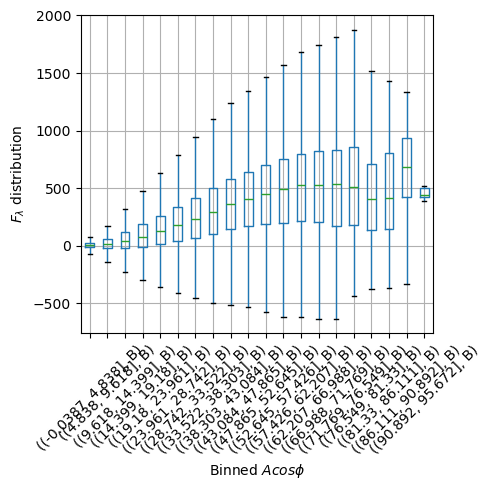

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

A = ds['dw_lwa'].loc[:,40:80,:].values.flatten()#mean(dim=['lon','lat'])

B = (ds['adv_flux_f1'] + ds['adv_flux_f2'] + ds['adv_flux_f3']).loc[:,40:80,:].values.flatten()#mean(dim=['lon','lat'])

print(A.shape,B.shape)

# Convert xarray DataArrays to DataFrame
df = pd.DataFrame({'A': A, 'B': B})

# Bin A into 15 equal-width intervals
df['A_binned'] = pd.cut(df['A'], bins=20)

# Group by A_binned
grouped = df.groupby('A_binned')

# Plot boxplots of B for each A bin
fig, ax = plt.subplots(figsize=(5, 5))
grouped.boxplot(column='B', subplots=False, ax=ax, rot=45,  showfliers=False)

ax.set_xlabel(r'Binned $Acos{\phi}$')
ax.set_ylabel(r'$F_{\lambda}$ distribution')
plt.grid(True)
plt.tight_layout()
plt.show()

7.824098080330525


Text(0, 0.5, 'counts')

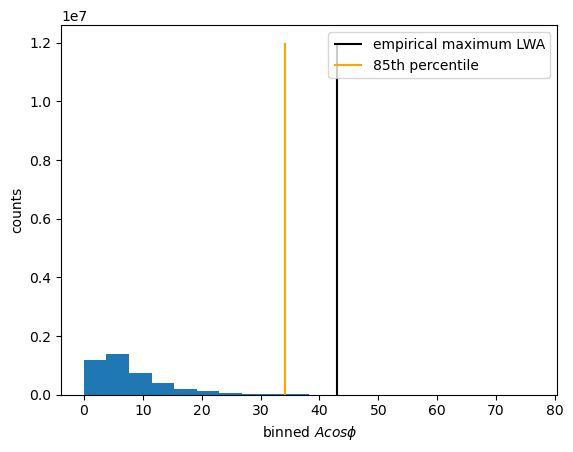

In [4]:
print(np.mean(A))

plt.hist(A,bins=20)
percentile = np.percentile(A,99.5)
plt.vlines(43,0,1.2e7,color='black',label='empirical maximum LWA')
plt.vlines(percentile,0,1.2e7,color='orange',label='85th percentile')
plt.legend()
plt.xlabel(r'binned $Acos{\phi}$')
plt.ylabel(r'counts')